In [4]:
import sys, os
from glob import glob

print("Python:", sys.version.split()[0])
print("Executable:", sys.executable)
print("CWD:", os.getcwd())
print("Matches:", glob("../data/raw/buenos-aires-real-estate-*.csv"))

Python: 3.12.3
Executable: /workspaces/Buenos_Aires_price_prediction_using_Linear_Regression/.venv/bin/python
CWD: /workspaces/Buenos_Aires_price_prediction_using_Linear_Regression/notebooks
Matches: ['../data/raw/buenos-aires-real-estate-5.csv', '../data/raw/buenos-aires-real-estate-2.csv', '../data/raw/buenos-aires-real-estate-4.csv', '../data/raw/buenos-aires-real-estate-1.csv', '../data/raw/buenos-aires-real-estate-3.csv']


# 2.1 Data Loading, Cleaning, and Feature Engineering

## 1. Import and Merge Multiple CSV Files

We load the five Buenos Aires housing CSVs from `../data/raw/` using `glob`, which
matches the `buenos-aires-real-estate-*.csv` pattern regardless of how many years
are present. `glob` keeps the pipeline self-updating if a sixth year is added later.

**Environment note:** Notebooks run from `notebooks/`, so paths begin with `../data/raw/`.

In [5]:
import pandas as pd
import numpy as np
from glob import glob

datasets = glob("../data/raw/buenos-aires-real-estate-*.csv")
datasets

['../data/raw/buenos-aires-real-estate-5.csv',
 '../data/raw/buenos-aires-real-estate-2.csv',
 '../data/raw/buenos-aires-real-estate-4.csv',
 '../data/raw/buenos-aires-real-estate-1.csv',
 '../data/raw/buenos-aires-real-estate-3.csv']

## 1. Load and merge the yearly CSVs

`glob` matches the wildcard pattern `buenos-aires-real-estate-*.csv` and returns every
matching path, so the pipeline keeps working if a sixth year is added. The CSVs are read
in a list comprehension and stacked once with `pd.concat(..., ignore_index=True)`.
`ignore_index=True` resets row indices to 0..N-1, avoiding duplicated index labels after the merge.

In [10]:
def merged_files(pattern):
    """Read every CSV matching `pattern` and stack into one DataFrame."""
    return pd.concat(
        [pd.read_csv(file) for file in glob(pattern)],
        ignore_index=True,
    )

In [11]:
df = merged_files("../data/raw/buenos-aires-real-estate-*.csv")
print("raw merged shape:", df.shape)
df.info()

raw merged shape: (43029, 16)
<class 'pandas.DataFrame'>
RangeIndex: 43029 entries, 0 to 43028
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   operation                   43029 non-null  str    
 1   property_type               43029 non-null  str    
 2   place_with_parent_names     43029 non-null  str    
 3   lat-lon                     34734 non-null  str    
 4   price                       38073 non-null  float64
 5   currency                    38072 non-null  str    
 6   price_aprox_local_currency  38073 non-null  float64
 7   price_aprox_usd             38073 non-null  float64
 8   surface_total_in_m2         29871 non-null  float64
 9   surface_covered_in_m2       36420 non-null  float64
 10  price_usd_per_m2            24449 non-null  float64
 11  price_per_m2                32642 non-null  float64
 12  floor                       6505 non-null   float64
 13  rooms       

## 2. Filter to a homogeneous market segment

The raw data spans Capital Federal and Greater Buenos Aires, apartments and houses,
and a long luxury price tail. Linear regression assumes a single pricing relationship,
so we narrow to one coherent segment:

- **Capital Federal** — the urban core, where size + location drive price
- **apartment** — houses and commercial spaces follow different pricing mechanics
- **price < $400,000** — excludes luxury outliers driven by features we don't record

In [12]:
def filter_df(data):
    return (
        data
        .loc[lambda x: x["place_with_parent_names"].str.contains("Capital Federal", na=False)]
        .query('property_type == "apartment"')
        .query("price_aprox_usd < 400_000")
    )

print("before filter:", df.shape)
df = filter_df(df)
print("after filter :", df.shape)

before filter: (43029, 16)
after filter : (8774, 16)


## 3. Trim outliers on `surface_covered_in_m2`

OLS minimizes **squared** error, so a single extreme surface value can dominate the fit.
We keep rows between the 10th and 90th percentile. Quantiles are used instead of fixed
cutoffs so the filter adapts if the data distribution changes.

In [13]:
def outliers_df(data):
    return data.loc[
        lambda x: x["surface_covered_in_m2"].between(
            x["surface_covered_in_m2"].quantile(0.10),
            x["surface_covered_in_m2"].quantile(0.90),
        )
    ]

print("before outliers:", df.shape)
df = outliers_df(df)
print("after outliers :", df.shape)

before outliers: (8774, 16)
after outliers : (6507, 16)


## 4. Extract features from string columns

- `"lat-lon"` → `lat`, `lon` (float)
- `"place_with_parent_names"` → `neighborhood` (index 3 of the pipe-split path)

In [14]:
def modify_cols(data):
    return data.assign(
        lat=lambda x: x["lat-lon"].str.split(",", expand=True)[0].astype(float),
        lon=lambda x: x["lat-lon"].str.split(",", expand=True)[1].astype(float),
        neighborhood=lambda x: x["place_with_parent_names"].str.split("|", expand=True)[3],
    )

df = modify_cols(df)
df[["lat", "lon", "neighborhood"]].head()

,lat,lon,neighborhood
3,-34.564676,-58.455720,Belgrano
9,-34.618830,-58.437779,Caballito
18,-34.577168,-58.538654,Belgrano
20,-34.571526,-58.455637,Colegiales
21,-34.578688,-58.457358,Colegiales


## 5. Missing-value analysis

Two complementary views: (a) fraction missing per column, (b) co-occurrence of
missingness across rows. Columns missing >50% of rows are dropped rather than imputed —
imputing that much invents data.

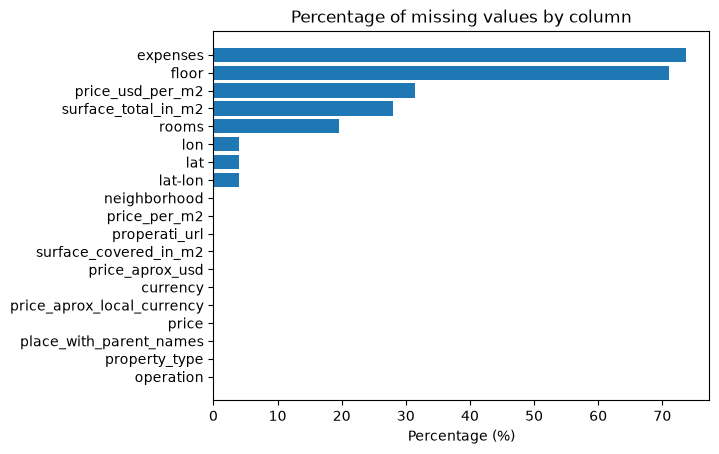

In [15]:
import matplotlib.pyplot as plt

nan_pct = (df.isna().sum(axis=0) * 100 / len(df)).sort_values()

fig, ax = plt.subplots()
ax.barh(y=nan_pct.index, width=nan_pct)
ax.set_title("Percentage of missing values by column")
ax.set_xlabel("Percentage (%)")
plt.show()

/workspaces/Buenos_Aires_price_prediction_using_Linear_Regression/.venv/lib/python3.12/site-packages/missingno/missingno.py:61: UserWarning: Plotting a sparkline on an existing axis is not currently supported. To remove this warning, set sparkline=False.
  warnings.warn(


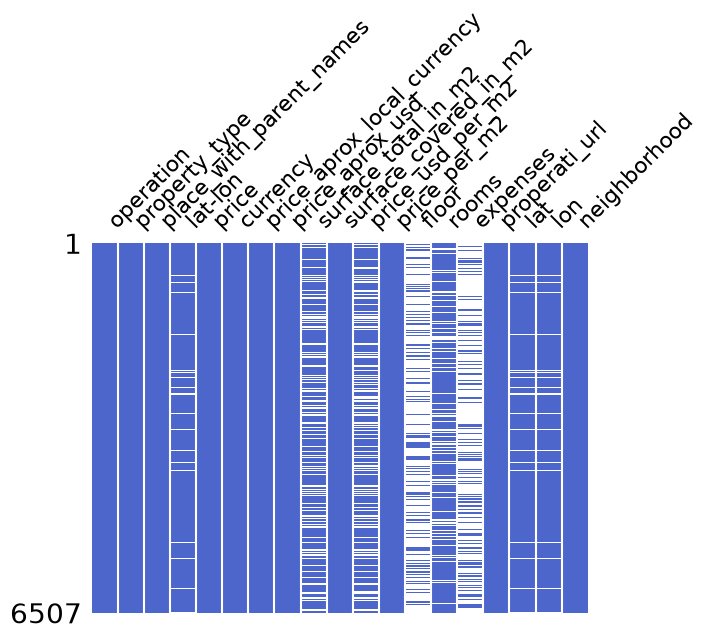

In [16]:
import missingno as msno

fig, ax = plt.subplots()
msno.matrix(df, color=(0.3, 0.4, 0.8), ax=ax)
plt.show()

## 6. Multicollinearity check

Highly correlated features make OLS coefficients unstable (the design matrix becomes
nearly singular). The heatmap below shows the price-derived columns correlated with the
target near ±1.0 — those are **leakage** and will be dropped. `surface_total_in_m2` is
also dropped on conceptual grounds: covered area is a subset of total area.

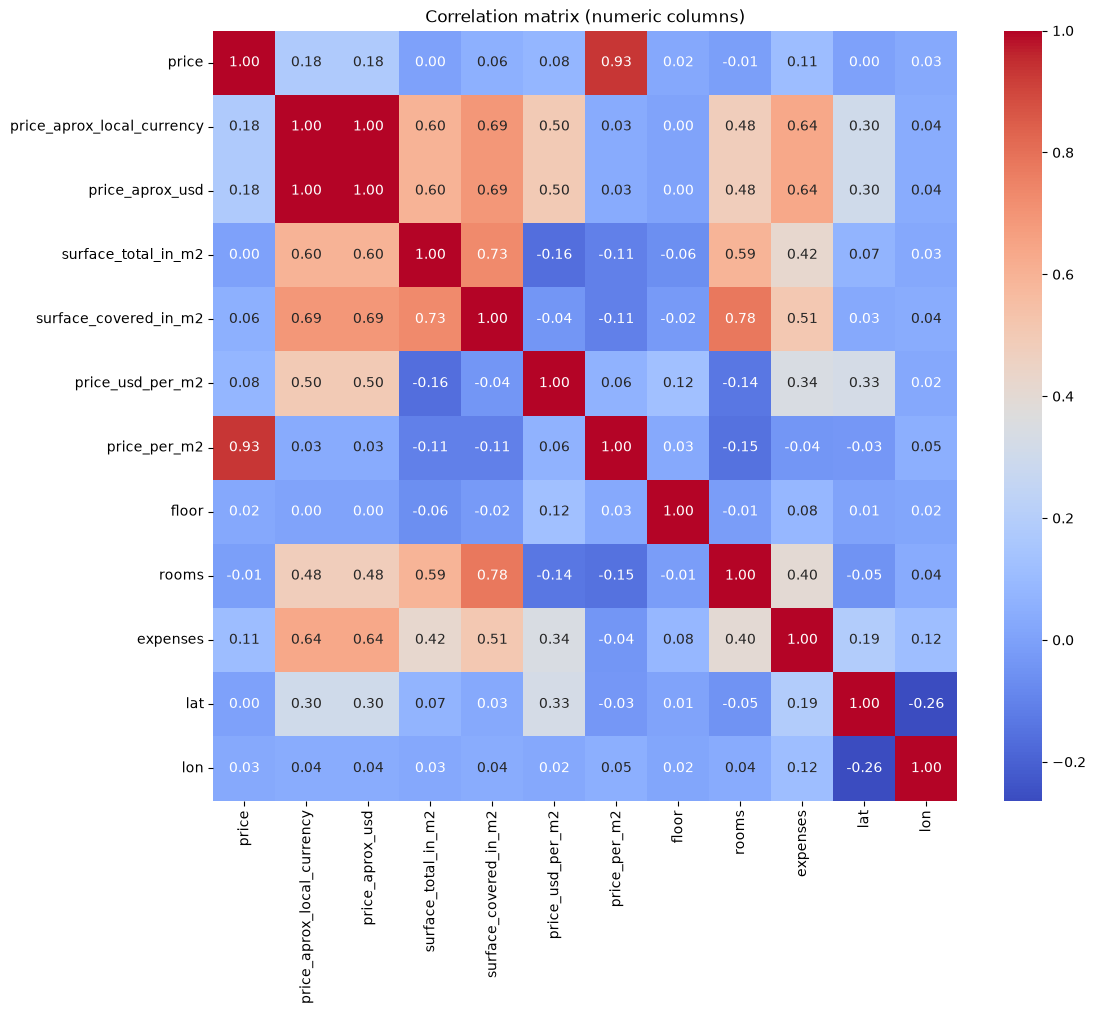

In [17]:
import seaborn as sns

corr = df.select_dtypes(include="number").corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Correlation matrix (numeric columns)")
plt.show()

## 7. Drop columns and finalize the pipeline

Columns removed and why:

| Category | Columns | Reason |
|---|---|---|
| High missingness (>50%) | `expenses`, `floor`, `rooms` | Imputing majority-missing columns invents data |
| Leakage | `price`, `price_aprox_local_currency`, `price_usd_per_m2`, `price_per_m2` | Derived from the target; would let the model "read the answer" |
| Multicollinearity | `surface_total_in_m2` | Redundant with `surface_covered_in_m2` |
| Identifier | `properati_url` | Unique per row; memorization target |
| Already extracted | `lat-lon`, `place_with_parent_names` | Replaced by `lat`, `lon`, `neighborhood` |
| Zero variance | `operation`, `property_type`, `currency` | Filtered to a single value each |

All steps are bundled into `clean_files()` via `.pipe()` so every later lesson
starts from an identical DataFrame.

In [18]:
DROP_COLS = [
    "lat-lon", "place_with_parent_names",
    "floor", "expenses", "rooms", "price",
    "price_aprox_local_currency", "price_usd_per_m2",
    "price_per_m2", "operation", "property_type", "currency",
    "properati_url", "surface_total_in_m2",
]

def clean_files(pattern):
    return (
        merged_files(pattern)
        .pipe(filter_df)
        .pipe(outliers_df)
        .pipe(modify_cols)
        .drop(columns=DROP_COLS)
        .dropna()
        .reset_index(drop=True)
    )

clean_df = clean_files("../data/raw/buenos-aires-real-estate-*.csv")
print("clean shape:", clean_df.shape)
clean_df.info()
clean_df.head()

clean shape: (6247, 5)
<class 'pandas.DataFrame'>
RangeIndex: 6247 entries, 0 to 6246
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        6247 non-null   float64
 1   surface_covered_in_m2  6247 non-null   float64
 2   lat                    6247 non-null   float64
 3   lon                    6247 non-null   float64
 4   neighborhood           6247 non-null   str    
dtypes: float64(4), str(1)
memory usage: 244.2 KB


,price_aprox_usd,surface_covered_in_m2,lat,lon,neighborhood
0,112000.0,60.0,-34.564676,-58.455720,Belgrano
1,76500.0,36.0,-34.618830,-58.437779,Caballito
2,90000.0,100.0,-34.577168,-58.538654,Belgrano
3,159900.0,77.0,-34.571526,-58.455637,Colegiales
4,123875.0,50.0,-34.578688,-58.457358,Colegiales


## 8. Features, target, and train/test split

- `X` = every column except `price_aprox_usd`
- `y` = `price_aprox_usd`
- 80/20 split, `random_state=42` — identical split reused in every later lesson

In [19]:
target = "price_aprox_usd"
features = [c for c in clean_df.columns if c != target]

X = clean_df[features]
y = clean_df[target]

print("X:", X.shape)
print("y:", y.shape)
print("features:", features)

X: (6247, 4)
y: (6247,)
features: ['surface_covered_in_m2', 'lat', 'lon', 'neighborhood']


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

assert len(X_train) + len(X_test) == len(X), "train+test ≠ total rows"
assert abs(len(X_test) / len(X) - 0.20) < 0.01, "test set not ~20%"
assert len(X_train) == len(y_train) and len(X_test) == len(y_test), "shape mismatch"
print("✅ train/test split verified")

X_train: (4997, 4) | X_test: (1250, 4)
y_train: (4997,) | y_test: (1250,)
✅ train/test split verified


## 9. Results

Pipeline outcomes (from this run):

- Raw merged rows: `<RAW>`
- After Capital Federal / apartment / <$400K filter: `<FILTERED>`
- After 10th–90th percentile surface filter: `<TRIMMED>`
- After `dropna()` on remaining columns: `<CLEAN>`
- Final features: `surface_covered_in_m2`, `lat`, `lon`, `neighborhood`
- Train / test rows: `<TRAIN>` / `<TEST>` (80/20, `random_state=42`)

**Sanity checks passed:** X/y shapes match, train+test = total, test fraction ≈ 20%.

## 10. Limitations

- **Market narrowed by design:** the model covers Capital Federal apartments under $400K only.
  It is not intended for houses, GBA, or luxury segments.
- **10% tails removed:** the model will under-predict very small and very large apartments
  because the training data deliberately excludes them.
- **Linear-assumption untested here:** this lesson only prepares the data. Whether a linear
  form is appropriate is examined in lesson 2.2 (baseline + linear regression).
- **No categorical encoding yet:** `neighborhood` is still a string in `X`; encoding happens
  inside the pipeline in lessons 2.3–2.4 so the encoder is fit on training data only.